In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/Users/nidagallusandeep/Downloads/day41_categorical_analysis.csv")
df.head()

,Order_ID,City,Category,Gender,Payment_Method,Order_Status,Marketing_Channel,Quantity,Unit_Price_INR,Revenue_INR
0,ORD001,Hyderabad,Grocery,Male,Debit Card,Delivered,Social Media,2,10868,21736
1,ORD002,Kurnool,Grocery,Female,Credit Card,Delivered,Social Media,6,10070,60420
2,ORD003,Vijayawada,Electronics,Female,Credit Card,Pending,Social Media,4,7449,29796
3,ORD004,Chennai,Grocery,Female,Cash,Delivered,Online,5,10422,52110
4,ORD005,Hyderabad,Grocery,Male,Cash,Cancelled,Social Media,4,9302,37208


In [3]:
df.shape
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Order_ID           60 non-null     object
 1   City               60 non-null     object
 2   Category           60 non-null     object
 3   Gender             60 non-null     object
 4   Payment_Method     60 non-null     object
 5   Order_Status       60 non-null     object
 6   Marketing_Channel  60 non-null     object
 7   Quantity           60 non-null     int64 
 8   Unit_Price_INR     60 non-null     int64 
 9   Revenue_INR        60 non-null     int64 
dtypes: int64(3), object(7)
memory usage: 4.8+ KB


,Order_ID,City,Category,Gender,Payment_Method,Order_Status,Marketing_Channel,Quantity,Unit_Price_INR,Revenue_INR
count,60,60,60,60,60,60,60,60.000000,60.000000,60.000000
unique,60,5,5,3,4,4,3,NaN,NaN,NaN
top,ORD001,Vijayawada,Grocery,Male,Debit Card,Delivered,Social Media,NaN,NaN,NaN
freq,1,19,20,35,16,40,21,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.583333,6891.166667,24513.233333
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.730011,3973.701208,19938.849910
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,428.000000,1634.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,3442.750000,10309.500000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,6267.000000,19046.500000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,10076.500000,32975.750000


In [5]:
cat_cols = df.select_dtypes(include="object").columns
print(cat_cols)

Index(['Order_ID', 'City', 'Category', 'Gender', 'Payment_Method',
       'Order_Status', 'Marketing_Channel'],
      dtype='object')


In [6]:
df["City"].unique()

array(['Hyderabad', 'Kurnool', 'Vijayawada', 'Chennai', 'Bengaluru'],
      dtype=object)

In [7]:
df["Category"].nunique()

5

In [8]:
df["City"].value_counts()

City
Vijayawada    19
Chennai       13
Kurnool       12
Bengaluru      9
Hyderabad      7
Name: count, dtype: int64

In [9]:
df["Category"].value_counts()

Category
Grocery        20
Clothing       14
Electronics    12
Furniture       8
Books           6
Name: count, dtype: int64

In [10]:
df["Payment_Method"].value_counts()

Payment_Method
Debit Card     16
Cash           16
UPI            16
Credit Card    12
Name: count, dtype: int64

In [11]:
df["Order_Status"].value_counts()

Order_Status
Delivered    40
Returned      9
Pending       7
Cancelled     4
Name: count, dtype: int64

In [12]:
df["Category"].value_counts(normalize=True) * 100

Category
Grocery        33.333333
Clothing       23.333333
Electronics    20.000000
Furniture      13.333333
Books          10.000000
Name: proportion, dtype: float64

In [13]:
df[cat_cols].isnull().sum()

Order_ID             0
City                 0
Category             0
Gender               0
Payment_Method       0
Order_Status         0
Marketing_Channel    0
dtype: int64

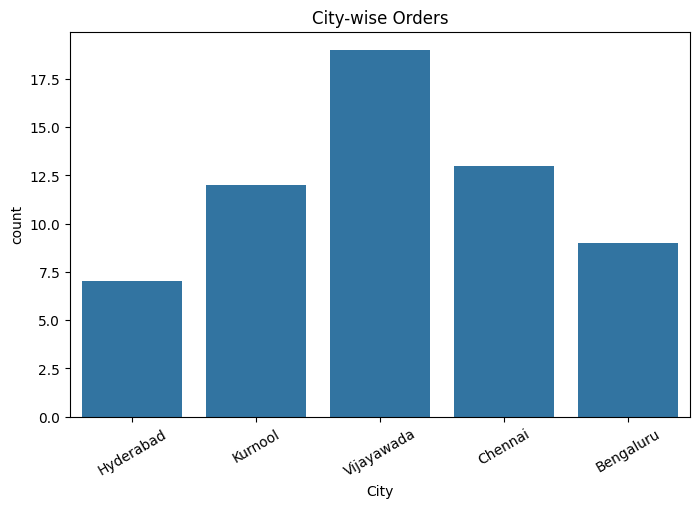

In [14]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="City")
plt.title("City-wise Orders")
plt.xticks(rotation=30)
plt.show()

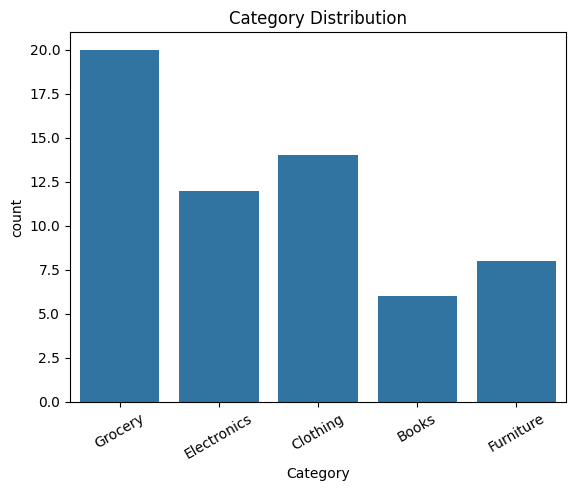

In [15]:
sns.countplot(data=df, x="Category")
plt.title("Category Distribution")
plt.xticks(rotation=30)
plt.show()

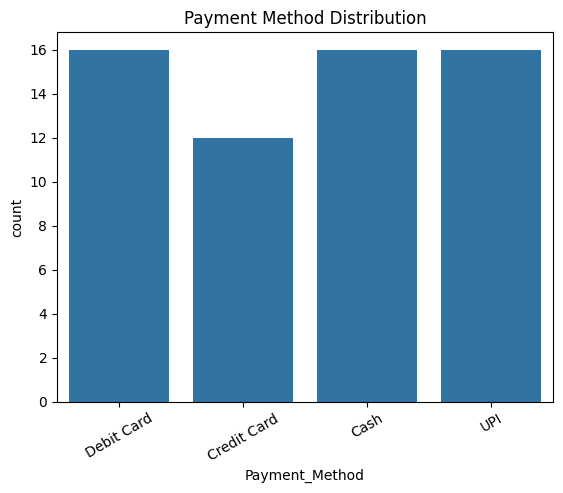

In [16]:
sns.countplot(data=df, x="Payment_Method")
plt.title("Payment Method Distribution")
plt.xticks(rotation=30)
plt.show()

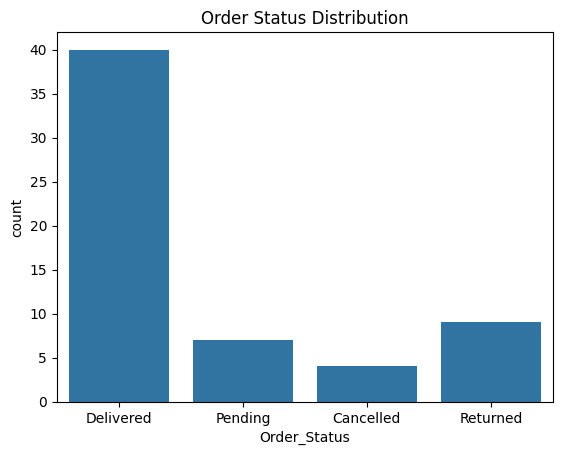

In [17]:
sns.countplot(data=df, x="Order_Status")
plt.title("Order Status Distribution")
plt.show()

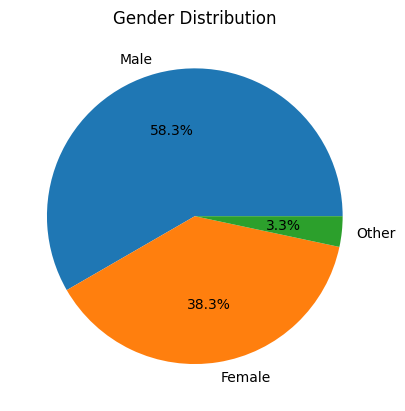

In [18]:
gender_counts = df["Gender"].value_counts()
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%")
plt.title("Gender Distribution")
plt.show()

In [20]:
df.groupby("Category")["Revenue_INR"].sum().sort_values(ascending=False)

Category
Grocery        635778
Clothing       338594
Electronics    194366
Furniture      162782
Books          139274
Name: Revenue_INR, dtype: int64

In [21]:
df.groupby("City")["Revenue_INR"].mean()

City
Bengaluru     31808.333333
Chennai       22771.461538
Hyderabad     22918.285714
Kurnool       24971.666667
Vijayawada    22547.473684
Name: Revenue_INR, dtype: float64

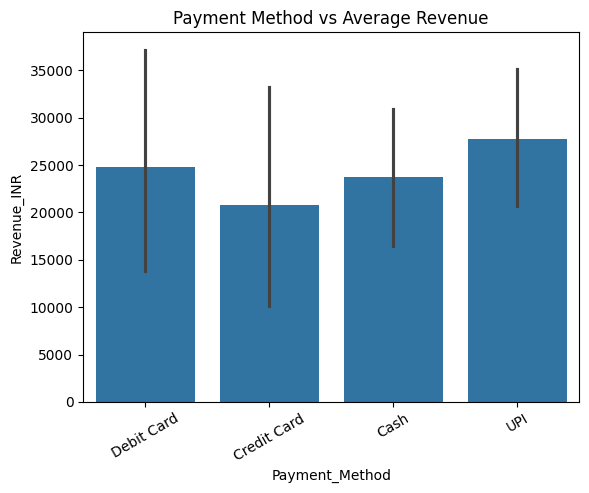

In [22]:
sns.barplot(
    data=df,
    x="Payment_Method",
    y="Revenue_INR"
)

plt.xticks(rotation=30)
plt.title("Payment Method vs Average Revenue")
plt.show()

In [23]:
pd.crosstab(df["City"], df["Category"])

Category,Books,Clothing,Electronics,Furniture,Grocery
City,,,,,
Bengaluru,0,4,0,2,3
Chennai,1,3,5,1,3
Hyderabad,2,0,2,0,3
Kurnool,1,2,2,3,4
Vijayawada,2,5,3,2,7


In [24]:
pd.crosstab(
    df["Payment_Method"],
    df["Order_Status"])

Order_Status,Cancelled,Delivered,Pending,Returned
Payment_Method,,,,
Cash,2,10,2,2
Credit Card,0,8,2,2
Debit Card,1,10,2,3
UPI,1,12,1,2


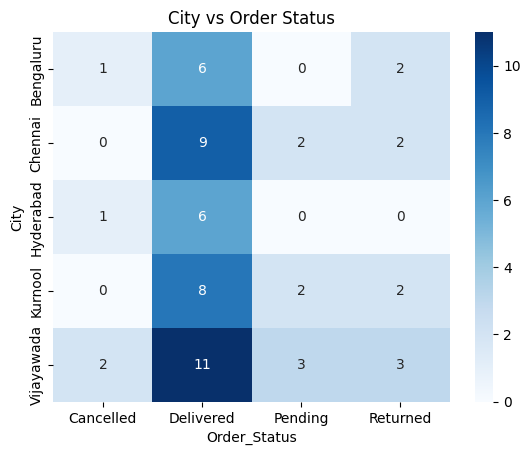

In [25]:
table = pd.crosstab(df["City"], df["Order_Status"])
sns.heatmap(table, annot=True, fmt="d", cmap="Blues")
plt.title("City vs Order Status")
plt.show()

In [26]:
df.groupby(["City", "Category"]).agg(
    Total_Orders=("Order_ID", "count"),
    Total_Revenue=("Revenue_INR", "sum"),
    Average_Revenue=("Revenue_INR", "mean")
).sort_values("Total_Revenue", ascending=False)

Total_Orders  Total_Revenue  Average_Revenue
City       Category                                                 
Chennai    Grocery                 3         151206     50402.000000
Kurnool    Grocery                 4         145854     36463.500000
Vijayawada Clothing                5         139742     27948.400000
Bengaluru  Grocery                 3         132643     44214.333333
           Clothing                4         121204     30301.000000
Vijayawada Grocery                 7         103181     14740.142857
Hyderabad  Grocery                 3         102894     34298.000000
Chennai    Electronics             5          79824     15964.800000
Vijayawada Books                   2          77057     38528.500000
           Electronics             3          69027     23009.000000
Kurnool    Furniture               3          68485     22828.333333
           Clothing                2          53618     26809.000000
Vijayawada Furniture               2          39395     19697.500000
Hyderabad  Electronics             2          32880     16440.000000
Bengaluru  Furniture               2          32428     16214.000000
Hyderabad  Books                   2          24654     12327.000000
Chennai    Clothing                3          24030      8010.000000
           Furniture               1          22474     22474.000000
Kurnool    Books                   1          19068     19068.000000
Chennai    Books                   1          18495     18495.000000
Kurnool    Electronics             2          12635      6317.500000